#### **Libraries and modules**

In [50]:
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pathlib import Path
from datetime import datetime
from cmcrameri import cm as cmc

#### **Load AIFS-ENS and ERA5 data**

In [51]:
# Load AIFS dataset
AIFS_filename_pl = "AIFS-ENS_02_Foehn_SouthAmerica_pl_2025-11-17_18UTC.nc"
ds_AIFS_pl = xr.open_dataset(AIFS_filename_pl)

# Load ERA5 dataset
ERA5_filename_pl = "ERA5_02_Foehn_SouthAmerica_pl_2025-11-17_18UTC.nc"
ds_ERA5_pl = xr.open_dataset(ERA5_filename_pl)


#### **Convert temperature from Kelvin to °C in the xarray dataset**

In [52]:
# Wind speed at pressure levels AIFS
ds_AIFS_pl["temperature_in_celsius"] = ds_AIFS_pl["t"] - 273.15

# Wind speed at pressure levels ERA5
ds_ERA5_pl["temperature_in_celsius"] = ds_ERA5_pl["t"] - 273.15

#### **Select the target time (valid time of forecast)**

In [53]:
target_time = pd.to_datetime("2025-11-17_18UTC", format="%Y-%m-%d_%HUTC")

#### **Locate max. temperature in ERA5**

In [54]:
# Max. temperature at 500 hPa in ERA5
temperature_max_500hPa_ERA5_pl = ds_ERA5_pl["temperature_in_celsius"].sel(isobaricInhPa=500, method="nearest").squeeze()

# Find index of maximum without converting the whole array to a scalar
max_flat_idx = int(np.nanargmax(temperature_max_500hPa_ERA5_pl.values))
max_idx = np.unravel_index(max_flat_idx, temperature_max_500hPa_ERA5_pl.shape)

lat_max_500hPa_ERA5_pl = float(temperature_max_500hPa_ERA5_pl.latitude.values[max_idx[0]])
lon_max_500hPa_ERA5_pl = float(temperature_max_500hPa_ERA5_pl.longitude.values[max_idx[1]])

# Extract the scalar max temperature value at the found index
temperature_max_500hPa_ERA5_pl_value = float(temperature_max_500hPa_ERA5_pl.values[max_idx])
print(f"ERA5 max. temperature at 500 hPa: {temperature_max_500hPa_ERA5_pl_value:.2f} °C")
print(f"Location (lat, lon): ({lat_max_500hPa_ERA5_pl:.2f}, {lon_max_500hPa_ERA5_pl:.2f})")

ERA5 max. temperature at 500 hPa: -5.06 °C
Location (lat, lon): (-41.00, -68.25)


#### **Subset AIFS temperature at the location of ERA5 max. temperature**

In [55]:
# Convert longitude from ERA5 to AIFS convention (0 to 360) for 500 hPa
lon_max_aifs_500pl = lon_max_500hPa_ERA5_pl % 360

# Find the closest forecast time in AIFS (pressure-level dataset) to the target time
target_time = np.datetime64("2025-11-17T18:00:00")
lead_idx = int(np.argmin(np.abs(ds_AIFS_pl["fc_valid_time"].values - target_time)))
lead_sel = ds_AIFS_pl["leadtime"].values[lead_idx]

# Extract the temperature (°C) at 500 hPa at the ERA5 maximum location for that lead time
aifs_temp_extreme_loc = ds_AIFS_pl["temperature_in_celsius"].sel(
    isobaricInhPa=500,
    latitude=lat_max_500hPa_ERA5_pl,
    longitude=lon_max_aifs_500pl,
    leadtime=lead_sel,
    method="nearest",
)

# Select the nearest AIFS grid point (all variables) at the ERA5 500 hPa max location for that lead time
aifs_point = ds_AIFS_pl.sel(
    isobaricInhPa=500,
    latitude=lat_max_500hPa_ERA5_pl,
    longitude=lon_max_aifs_500pl,
    leadtime=lead_sel,
    method="nearest",
)

# Select the AIFS temperature at the ERA5 max location (nearest grid point, all lead times)
ds_AIFS_pl_sel_temp = ds_AIFS_pl["temperature_in_celsius"].sel(
    isobaricInhPa=500,
    latitude=lat_max_500hPa_ERA5_pl,
    longitude=lon_max_aifs_500pl,
    method="nearest",
)

## **Plotting**

#### **Set output directory for all plots**

In [56]:
# Default output directory for all plots
PLOT_DIR = Path(
    r"C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc"
    r"\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks"
    r"\01_Case_Study\01_Code\01_Plots\02_temperature"
)

def save_plot(
    fig,
    plot_name,
    output_dir=PLOT_DIR,
    dpi=300
):
    """
    Save a Matplotlib figure as both PNG and PDF.

    PNG files are saved in:
        output_dir/png

    PDF files are saved in:
        output_dir/pdf

    Files are named:
        YYYYMMDD_wind_plot_name.png
        YYYYMMDD_wind_plot_name.pdf

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure that should be saved.
    plot_name : str
        Descriptive filename without the date or file extension.
    output_dir : str or pathlib.Path
        Main directory containing the PNG and PDF subfolders.
    dpi : int
        Resolution of the PNG file.
    """

    output_dir = Path(output_dir)

    # Separate output directories
    png_dir = output_dir / "01_png"
    pdf_dir = output_dir / "02_pdf"

    # Create directories if they do not already exist
    png_dir.mkdir(parents=True, exist_ok=True)
    pdf_dir.mkdir(parents=True, exist_ok=True)

    current_date = datetime.now().strftime("%Y%m%d")

    # Prevent unwanted spaces in filenames
    clean_plot_name = plot_name.strip().replace(" ", "_")

    filename = f"{current_date}_temperature_{clean_plot_name}"

    png_path = png_dir / f"{filename}.png"
    pdf_path = pdf_dir / f"{filename}.pdf"

    # High-resolution raster image
    fig.savefig(
        png_path,
        dpi=dpi,
        bbox_inches="tight"
    )

    # Vector image
    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    print(
        "Plots saved as:\n"
        f"PNG: {png_path}\n"
        f"PDF: {pdf_path}"
    )

    return png_path, pdf_path

### **Boxplots**

#### **Boxplot comparing AIFS ensemble 500 hPa temperatures with max. 500 hPa temperature in ERA5**  

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\02_temperature\01_png\20260723_temperature_boxplot_500hPa_AIFS_ERA5_max.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\02_temperature\02_pdf\20260723_temperature_boxplot_500hPa_AIFS_ERA5_max.pdf


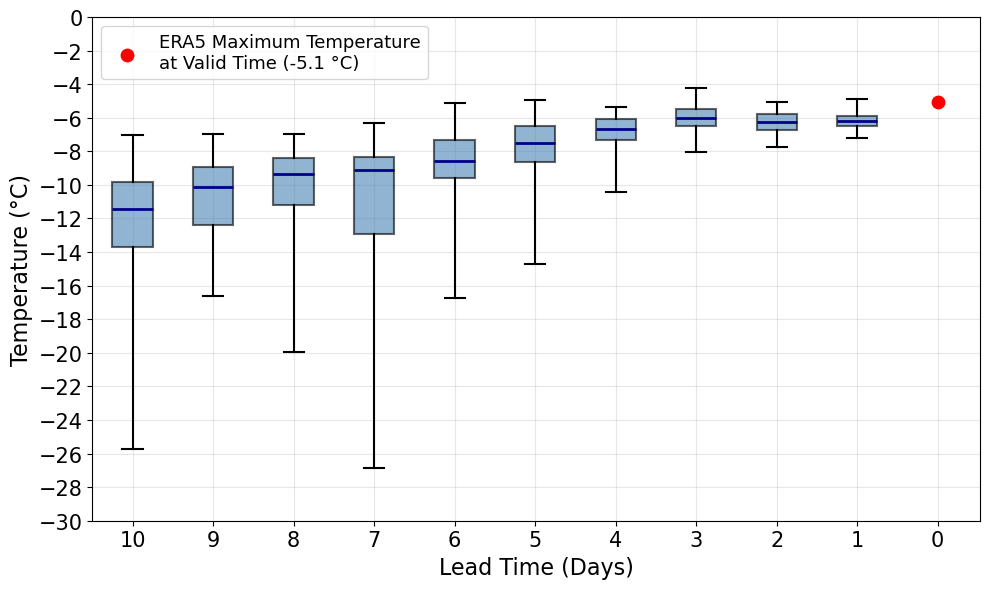

In [57]:
fig, ax = plt.subplots(figsize=(10, 6))

leadtimes = np.arange(1, 10 + 1, 1)
n_leads = len(leadtimes)

# Reverse data so lead time 10 days appears first
data_reversed = ds_AIFS_pl_sel_temp.values[:, ::-1]

box = ax.boxplot(
    data_reversed,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="steelblue",
        alpha=0.6,
        linewidth=1.5
    ),
    medianprops=dict(
        color="darkblue",
        linewidth=2
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point: maximum 500 hPa temperature
ax.scatter(
    n_leads + 1,
    temperature_max_500hPa_ERA5_pl_value,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Maximum Temperature\n"
        f"at Valid Time "
        f"({temperature_max_500hPa_ERA5_pl_value:.1f} °C)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = list(leadtimes[::-1]) + [0]

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)
ax.tick_params(axis="y", labelsize=15)

valid_time = pd.to_datetime(
    ds_AIFS_pl_sel_temp["fc_valid_time"].values[0]
)
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel("Temperature (°C)", fontsize=16)

# Fixed y-axis limits
ax.set_ylim(
    -30,
    0
)
ax.set_yticks(
    np.arange(
        -30,
        0 + 0.1,
        2
    )
)

ax.legend(fontsize=13, loc="upper left")
ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "boxplot_500hPa_AIFS_ERA5_max"
)

plt.show()
plt.close(fig)

#### **Boxplot comparing AIFS ensemble 500 hPa temperatures with max. 500 hPa temperature in ERA5 with spatial shift allowance - AIFS finds max. temperatures within ±2.0° lat, ±2.0° lon of the ERA5 maximum location**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\02_temperature\01_png\20260723_temperature_boxplot_500hPa_AIFS_ERA5_max_spatial_allowance.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\02_temperature\02_pdf\20260723_temperature_boxplot_500hPa_AIFS_ERA5_max_spatial_allowance.pdf


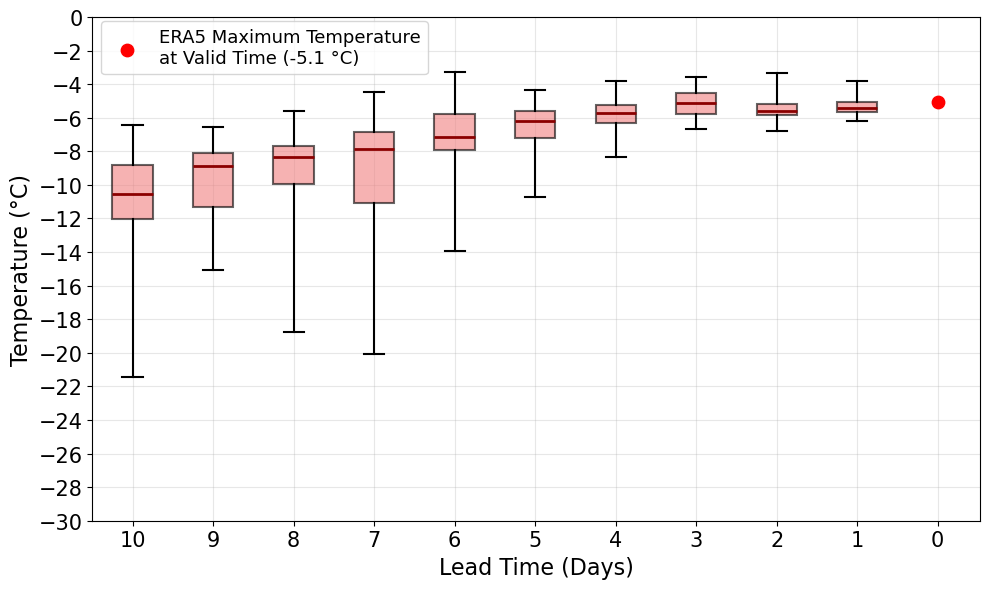

In [58]:
# Define search window around ERA5 500 hPa maximum
search_radius_lat = 2.0  # ±2.0° latitude
search_radius_lon = 2.0  # ±2.0° longitude

lat_center = lat_max_500hPa_ERA5_pl
lon_center = lon_max_500hPa_ERA5_pl % 360

lat_min = lat_center - search_radius_lat
lat_max = lat_center + search_radius_lat

# Select 500 hPa temperature
ds_AIFS_500hPa_temperature = ds_AIFS_pl[
    "temperature_in_celsius"
].sel(
    isobaricInhPa=500,
    method="nearest"
)

# Circular longitude distance, robust around 0°/360°
lon_distance = np.abs(
    (
        (
            ds_AIFS_500hPa_temperature["longitude"]
            - lon_center
            + 180
        )
        % 360
    )
    - 180
)

# Extract temperature within the search window for all ensemble
# members and lead times
ds_AIFS_500hPa_search_window = ds_AIFS_500hPa_temperature.where(
    (
        (ds_AIFS_500hPa_temperature["latitude"] >= lat_min)
        & (ds_AIFS_500hPa_temperature["latitude"] <= lat_max)
        & (lon_distance <= search_radius_lon)
    ),
    drop=True
)

# Find maximum temperature within the search window for each
# ensemble member and lead time
aifs_500hPa_temperature_max_in_window = (
    ds_AIFS_500hPa_search_window.max(
        dim=["latitude", "longitude"]
    )
)

fig, ax = plt.subplots(figsize=(10, 6))

# Use the actual lead-time coordinate
leadtimes = aifs_500hPa_temperature_max_in_window[
    "leadtime"
].values
n_leads = len(leadtimes)

# Convert lead-time labels to days when stored as timedelta64
if np.issubdtype(leadtimes.dtype, np.timedelta64):
    leadtime_days = (
        leadtimes / np.timedelta64(1, "D")
    ).astype(int)
else:
    leadtime_days = leadtimes.astype(int)

# Build one array per lead time, with longest lead time first
data_for_boxplot = []

for lt in leadtimes[::-1]:
    values = np.ravel(
        aifs_500hPa_temperature_max_in_window
        .sel(leadtime=lt)
        .values
    )

    # Remove possible missing values
    values = values[np.isfinite(values)]
    data_for_boxplot.append(values)

box = ax.boxplot(
    data_for_boxplot,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="lightcoral",
        alpha=0.6,
        linewidth=1.5
    ),
    medianprops=dict(
        color="darkred",
        linewidth=2
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point: maximum 500 hPa temperature
ax.scatter(
    n_leads + 1,
    temperature_max_500hPa_ERA5_pl_value,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Maximum Temperature\n"
        f"at Valid Time "
        f"({temperature_max_500hPa_ERA5_pl_value:.1f} °C)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = list(leadtime_days[::-1]) + [0]

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)
ax.tick_params(axis="y", labelsize=15)

valid_time = pd.to_datetime(
    aifs_500hPa_temperature_max_in_window[
        "fc_valid_time"
    ].values[0]
)
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel("Temperature (°C)", fontsize=16)

# Fixed y-axis limits
ax.set_ylim(
    -30,
    0
)
ax.set_yticks(
    np.arange(
        -30,
        0 + 0.1,
        2
    )
)

ax.legend(
    fontsize=13,
    loc="upper left",
    bbox_to_anchor=(0.0, 1.01)
)

ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "boxplot_500hPa_AIFS_ERA5_max_spatial_allowance"
)

plt.show()
plt.close(fig)

#### **Difference plot for 500 hPa temperature**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\02_temperature\01_png\20260723_temperature_difference_plot_500hPa_AIFS_ERA5_leadtimes.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\02_temperature\02_pdf\20260723_temperature_difference_plot_500hPa_AIFS_ERA5_leadtimes.pdf


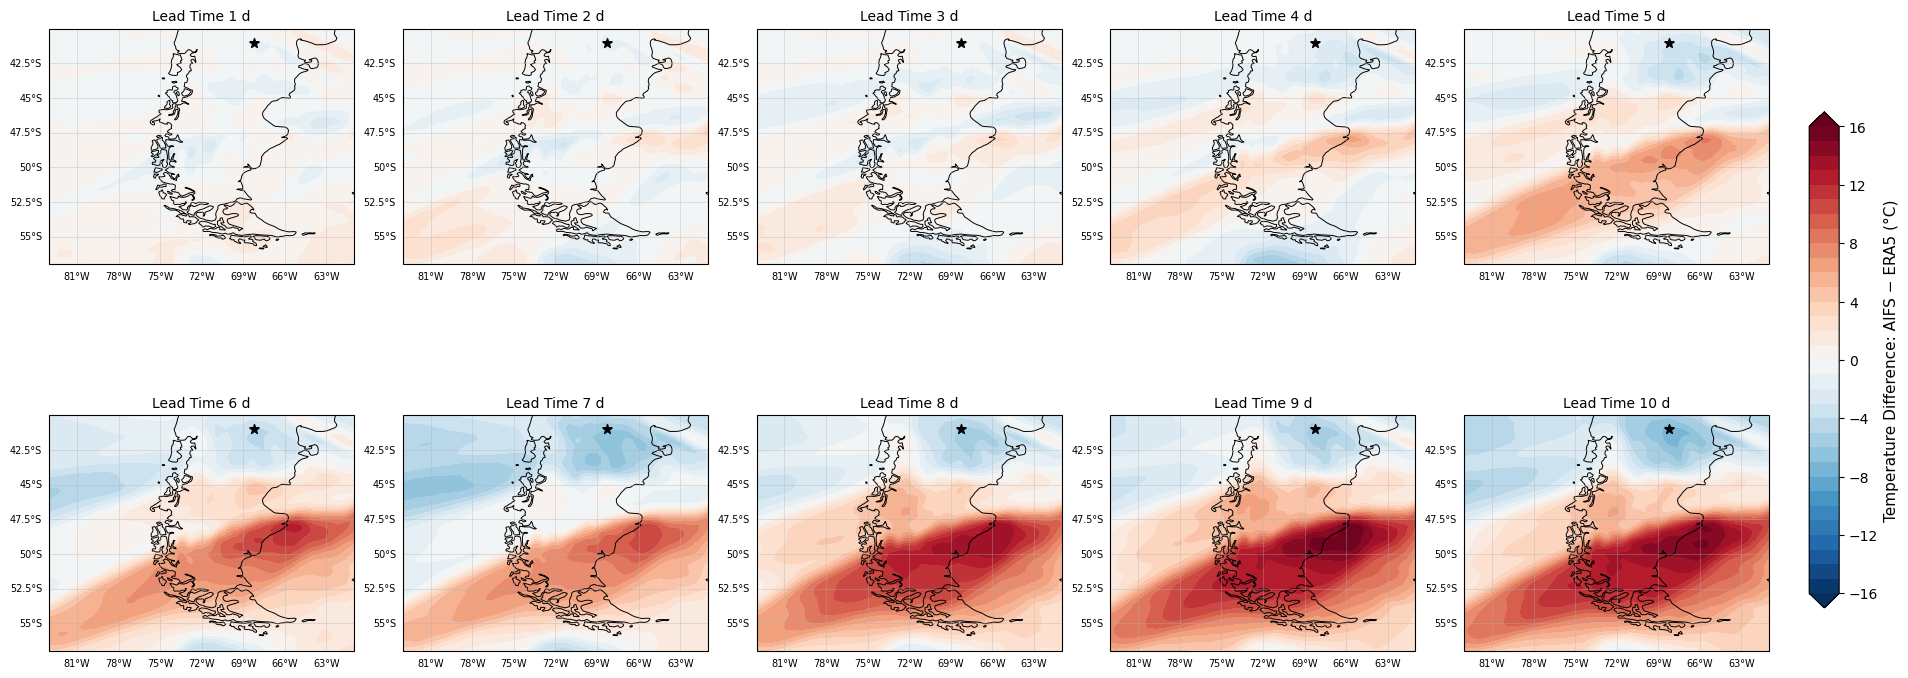

In [59]:
# 500 hPa temperature difference:
# AIFS ensemble mean minus ERA5
#
# Blue: AIFS ensemble mean is colder than ERA5
# Red:  AIFS ensemble mean is warmer than ERA5

# ------------------------------------------------------------------
# Use the exact same spatial extent as the wind difference plots
# ------------------------------------------------------------------

common_lat_min_temp_diff = -57.0
common_lat_max_temp_diff = -40.0
common_lon_min_temp_diff = 277.0
common_lon_max_temp_diff = 299.0

# ------------------------------------------------------------------
# Select the AIFS 500 hPa temperature field on the common map domain
# ------------------------------------------------------------------

ds_AIFS_500_temp_diff = (
    ds_AIFS_pl["temperature_in_celsius"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .sel(
        latitude=slice(
            common_lat_max_temp_diff,
            common_lat_min_temp_diff
        ),
        longitude=slice(
            common_lon_min_temp_diff,
            common_lon_max_temp_diff
        )
    )
)

# ------------------------------------------------------------------
# AIFS ensemble mean
# ------------------------------------------------------------------

aifs_500_temp_ens_mean_diff = (
    ds_AIFS_500_temp_diff
    .mean(dim="ensemble_members")
    .sortby("leadtime")
    .squeeze(drop=True)
)

# ------------------------------------------------------------------
# Prepare ERA5 500 hPa temperature
# ------------------------------------------------------------------

era5_500_temp_diff = (
    ds_ERA5_pl["temperature_in_celsius"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .squeeze(drop=True)
    .assign_coords(
        longitude=(
            ds_ERA5_pl["longitude"] % 360
        )
    )
    .sortby("latitude")
    .sortby("longitude")
)

# ERA5 field on the displayed domain
era5_500_temp_domain_diff = (
    era5_500_temp_diff.where(
        (
            (
                era5_500_temp_diff.latitude
                >= common_lat_min_temp_diff
            )
            & (
                era5_500_temp_diff.latitude
                <= common_lat_max_temp_diff
            )
            & (
                era5_500_temp_diff.longitude
                >= common_lon_min_temp_diff
            )
            & (
                era5_500_temp_diff.longitude
                <= common_lon_max_temp_diff
            )
        ),
        drop=True
    )
)

# ------------------------------------------------------------------
# Interpolate ERA5 onto the AIFS grid
# ------------------------------------------------------------------

era5_500_temp_on_aifs_diff = (
    era5_500_temp_diff.interp(
        latitude=aifs_500_temp_ens_mean_diff.latitude,
        longitude=aifs_500_temp_ens_mean_diff.longitude
    )
)

# ------------------------------------------------------------------
# Calculate AIFS ensemble-mean minus ERA5 temperature difference
# ------------------------------------------------------------------

temperature_500_difference = (
    aifs_500_temp_ens_mean_diff
    - era5_500_temp_on_aifs_diff
).transpose(
    "leadtime",
    "latitude",
    "longitude"
)

temperature_500_difference.name = (
    "temperature_500_difference"
)

# Check that the interpolation produced valid values
n_finite_500_temp_difference_values = int(
    np.isfinite(
        temperature_500_difference.values
    ).sum()
)

if n_finite_500_temp_difference_values == 0:
    raise ValueError(
        "The ERA5-to-AIFS interpolation produced no "
        "finite values. Check the latitude and longitude "
        "coordinates."
    )

# ------------------------------------------------------------------
# Find the ERA5 maximum temperature within the displayed domain
# ------------------------------------------------------------------

era5_500_temp_stacked_diff = (
    era5_500_temp_domain_diff.stack(
        gridpoint=(
            "latitude",
            "longitude"
        )
    )
)

era5_500_temp_max_index_diff = int(
    era5_500_temp_stacked_diff.argmax(
        dim="gridpoint",
        skipna=True
    ).values
)

era5_500_temp_max_point_diff = (
    era5_500_temp_stacked_diff.isel(
        gridpoint=era5_500_temp_max_index_diff
    )
)

era5_500_temp_max_value_diff = float(
    era5_500_temp_max_point_diff.values
)

era5_500_temp_max_lat_diff = float(
    era5_500_temp_max_point_diff[
        "latitude"
    ].values
)

era5_500_temp_max_lon_diff = float(
    era5_500_temp_max_point_diff[
        "longitude"
    ].values
)

# ------------------------------------------------------------------
# Prepare lead-time labels
# ------------------------------------------------------------------

leadtimes_500_temp_diff = (
    aifs_500_temp_ens_mean_diff[
        "leadtime"
    ].values
)

n_leadtimes_500_temp_diff = len(
    leadtimes_500_temp_diff
)

if n_leadtimes_500_temp_diff == 0:
    raise ValueError(
        "No AIFS lead times were found."
    )

if n_leadtimes_500_temp_diff > 10:
    raise ValueError(
        "The 2 × 5 layout supports a maximum of "
        "10 AIFS lead times."
    )

if np.issubdtype(
    leadtimes_500_temp_diff.dtype,
    np.timedelta64
):
    leadtime_days_500_temp_diff = (
        leadtimes_500_temp_diff
        / np.timedelta64(1, "D")
    ).astype(int)

else:
    leadtime_days_500_temp_diff = (
        leadtimes_500_temp_diff.astype(int)
    )

# ------------------------------------------------------------------
# Create one common symmetric temperature-difference scale
# ------------------------------------------------------------------

difference_abs_max_500_temp = float(
    np.abs(
        temperature_500_difference
    ).max(
        skipna=True
    ).compute().values
)

if not np.isfinite(
    difference_abs_max_500_temp
):
    raise ValueError(
        "The 500 hPa temperature difference contains "
        "no finite values."
    )

# Use 1 °C intervals
difference_step_500_temp = 1.0

# Round upward to the next whole degree Celsius
difference_limit_500_temp = max(
    difference_step_500_temp,
    float(
        np.ceil(
            difference_abs_max_500_temp
        )
    )
)

difference_levels_500_temp = np.arange(
    -difference_limit_500_temp,
    difference_limit_500_temp
    + difference_step_500_temp,
    difference_step_500_temp
)

# ------------------------------------------------------------------
# Create figure: 2 rows × 5 columns
# ------------------------------------------------------------------

map_projection = ccrs.PlateCarree()

fig, axes = plt.subplots(
    2,
    5,
    figsize=(20, 8),
    subplot_kw={
        "projection": map_projection
    }
)

axes = axes.flatten()

fig.subplots_adjust(
    left=0.04,
    right=0.90,
    bottom=0.08,
    top=0.95,
    wspace=0.16,
    hspace=0.25
)

# ------------------------------------------------------------------
# Difference panels
# ------------------------------------------------------------------

for i, lt in enumerate(
    leadtimes_500_temp_diff
):
    ax = axes[i]

    difference_500_temp_sel = (
        temperature_500_difference.sel(
            leadtime=lt
        )
    )

    ax.set_extent(
        [
            common_lon_min_temp_diff,
            common_lon_max_temp_diff,
            common_lat_min_temp_diff,
            common_lat_max_temp_diff
        ],
        crs=map_projection
    )

    # Temperature-difference background
    cf_500_temp_diff = ax.contourf(
        difference_500_temp_sel.longitude,
        difference_500_temp_sel.latitude,
        difference_500_temp_sel,
        levels=difference_levels_500_temp,
        cmap="RdBu_r",
        extend="both",
        transform=map_projection
    )

    # ERA5 maximum-temperature location
    ax.scatter(
        era5_500_temp_max_lon_diff,
        era5_500_temp_max_lat_diff,
        marker="*",
        color="black",
        s=50,
        transform=map_projection,
        zorder=6
    )

    # Coastlines
    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7
    )

    ax.set_title(
        f"Lead Time "
        f"{leadtime_days_500_temp_diff[i]} d",
        fontsize=10
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        alpha=0.5
    )

    gl.left_labels = True
    gl.bottom_labels = True
    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 7
    }

    gl.ylabel_style = {
        "size": 7
    }

    gl.xpadding = 5
    gl.ypadding = 5

# Hide unused panels if fewer than ten lead times exist
for panel_index in range(
    n_leadtimes_500_temp_diff,
    len(axes)
):
    axes[
        panel_index
    ].set_visible(False)

# ------------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------------

cbar_ax = fig.add_axes([
    0.92,
    0.18,
    0.015,
    0.62
])

cbar = fig.colorbar(
    cf_500_temp_diff,
    cax=cbar_ax,
    boundaries=difference_levels_500_temp,
    spacing="proportional",
    extend="both",
    extendfrac="auto"
)

cbar.set_label(
    "Temperature Difference: "
    "AIFS − ERA5 (°C)",
    fontsize=11
)

cbar.ax.tick_params(
    labelsize=10
)

# ------------------------------------------------------------------
# Save and display
# ------------------------------------------------------------------

png_path, pdf_path = save_plot(
    fig,
    "difference_plot_500hPa_AIFS_ERA5_leadtimes"
)

plt.show()
plt.close(fig)